In [1]:
library(lme4)
library(lmerTest)
library(emmeans)
library(dplyr)

Loading required package: Matrix

Warning message:
“package ‘Matrix’ was built under R version 4.4.3”
Warning message:
“package ‘lmerTest’ was built under R version 4.4.3”

Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘package:stats’:

    step


Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
df <- read.csv("concatenated_data/f0_z_onset_offset_processed.csv")

df$tone <- as.factor(df$tone)
df$lang <- as.factor(df$lang)
df$onset_segment_type <- as.factor(df$onset_segment)
df$offset_segment_type <- as.factor(df$offset_segment)
df$position <- as.factor(df$position)
df$participant <- as.factor(df$participant)
df$onset_portion_idx <- scale(df$onset_portion_idx)
df$offset_portion_idx <- scale(df$offset_portion_idx)

## Overall

In [3]:
contrasts(df$tone) <- contr.sum(length(unique(df$tone)))
print(contrasts(df$tone))

contrasts(df$lang) <- contr.sum(length(unique(df$lang)))
print(contrasts(df$lang))

# contrasr code as -0.5 and 0.5
contrasts(df$position) <- c(-0.5, 0.5)
print(contrasts(df$position))

   [,1] [,2] [,3] [,4]
21    1    0    0    0
33    0    1    0    0
35    0    0    1    0
51    0    0    0    1
55   -1   -1   -1   -1
              [,1] [,2]
man              1    0
man_bilingual    0    1
min             -1   -1
             [,1]
anticipatory -0.5
carryover     0.5


In [4]:
temp <- df

model <- lmer(y ~ x*lang*tone*position*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 40 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 200 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
y ~ x * lang * tone * position * onset_portion_idx * offset_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 27224.7

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-6.5489 -0.4374 -0.0091  0.4371  6.4442 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 1.503e-02 0.122589      
                     x           1.502e-02 0.122559 -0.38
 offset_segment_type (Intercept) 6.394e-03 0.079961      
                     x           6.720e-03 0.081973 -0.70
 onset_segment_type  (Intercept) 2.199e-03 0.046889      
                     x           1.085e-06 0.001042 -1.00
 Residual                        5.866e-01 0.765889      
Number of obs: 11374, groups:  
participant, 25; offset_segment_type, 4; onset_segment_type, 2

Fixed effect

### Residual analysis

Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
`geom_smooth()` using formula = 'y ~ x'


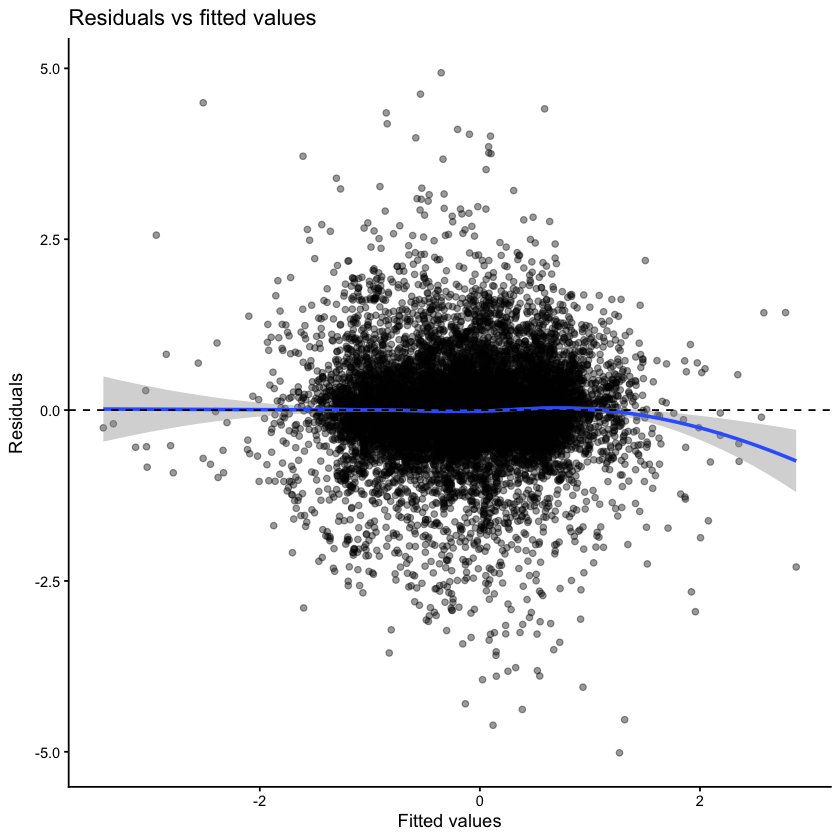

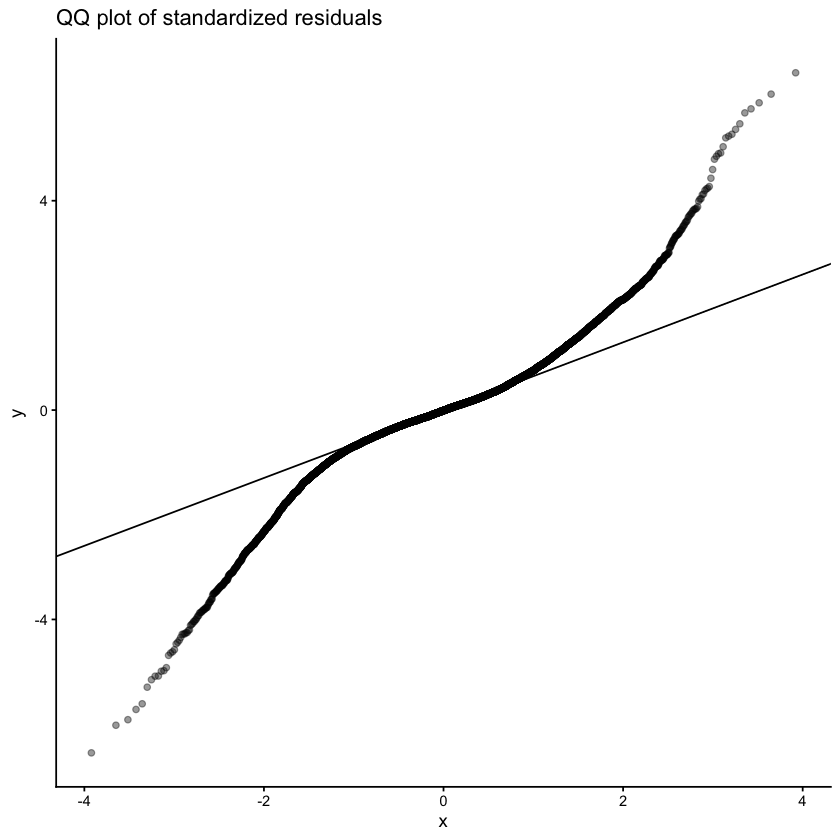

`geom_smooth()` using formula = 'y ~ x'


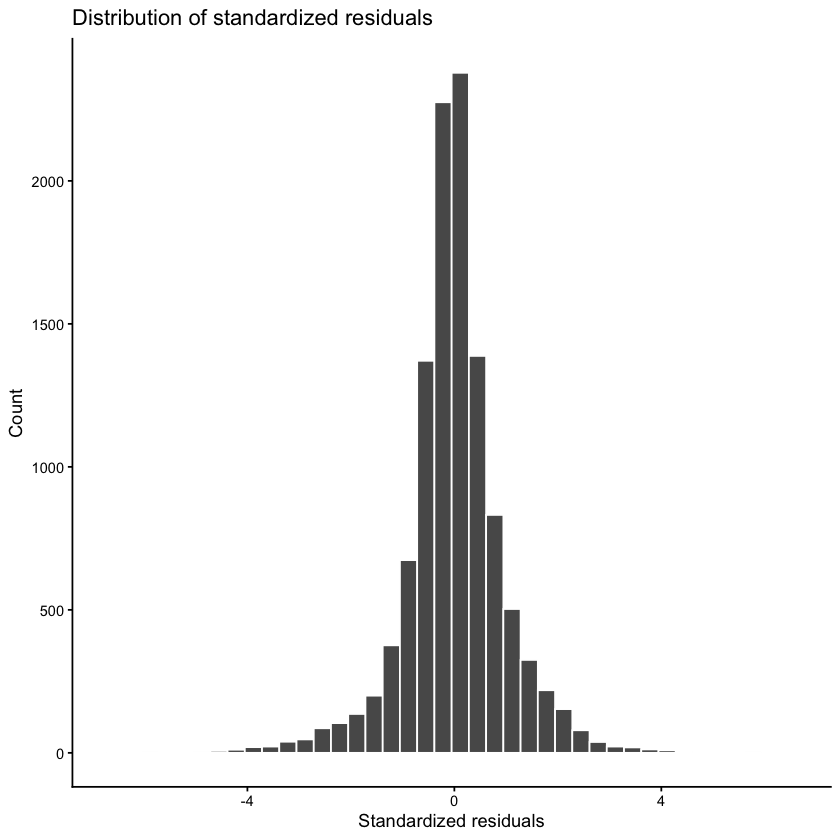

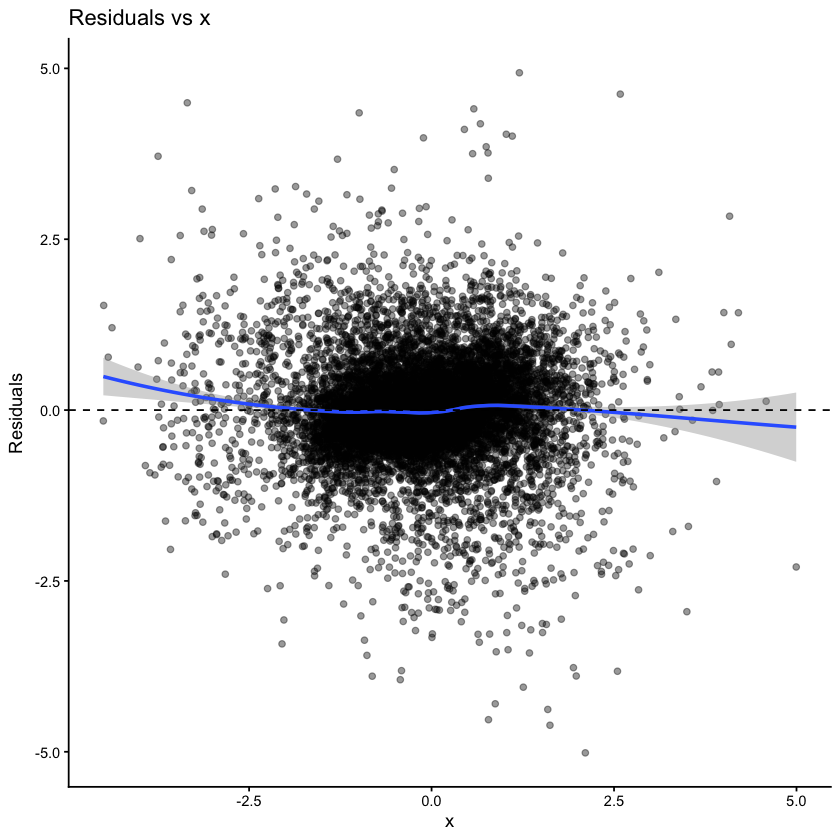

In [5]:
library(ggplot2)
diag_df <- model.frame(model) %>%
  mutate(
    fitted = fitted(model),
    resid = resid(model),
    pearson_resid = residuals(model, type = "pearson"),
    std_resid = resid / sigma(model),

    
    abs_std_resid = abs(std_resid)
  )

ggplot(diag_df, aes(x = fitted, y = resid)) +
  geom_point(alpha = 0.4) +
  geom_smooth(method = "loess", se = TRUE) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  theme_classic() +
  labs(
    x = "Fitted values",
    y = "Residuals",
    title = "Residuals vs fitted values"
  )

ggplot(diag_df, aes(sample = std_resid)) +
  stat_qq(alpha = 0.4) +
  stat_qq_line() +
  theme_classic() +
  labs(title = "QQ plot of standardized residuals")

ggplot(diag_df, aes(x = std_resid)) +
  geom_histogram(bins = 40, color = "white") +
  theme_classic() +
  labs(
    x = "Standardized residuals",
    y = "Count",
    title = "Distribution of standardized residuals"
  )

ggplot(diag_df, aes(x = x, y = resid)) +
  geom_point(alpha = 0.4) +
  geom_smooth(method = "loess", se = TRUE) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  theme_classic() +
  labs(
    x = "x",
    y = "Residuals",
    title = "Residuals vs x"
  )

### Excluding outliers

In [6]:
library(dplyr)

df$model_resid <- resid(model)
# Standardize the residuals and filter out extremes (keeping those within 2.5 SDs)
df_clean <- df %>%
  filter(abs(scale(model_resid)) < 2.5)

print(nrow(df) - nrow(df_clean))
# percentage
print((nrow(df) - nrow(df_clean)) / nrow(df) * 100)

Warning message:
“Using one column matrices in `filter()` was deprecated in dplyr 1.1.0.
ℹ Please use one dimensional logical vectors instead.”


[1] 362
[1] 3.182697


In [7]:
model <- lmer(y ~ x*lang*tone*position*onset_portion_idx*offset_portion_idx + 
                      (x | onset_segment_type) + 
                      (x | offset_segment_type) + 
                      (x | participant), 
                    data = df_clean)

summary(model)

fixed-effect model matrix is rank deficient so dropping 40 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 200 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
y ~ x * lang * tone * position * onset_portion_idx * offset_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: df_clean

REML criterion at convergence: 21190

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-4.1591 -0.5016 -0.0249  0.4817  3.4374 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 1.326e-02 0.11514       
                     x           1.542e-02 0.12420  -0.06
 offset_segment_type (Intercept) 5.915e-03 0.07691       
                     x           7.311e-03 0.08550  -0.49
 onset_segment_type  (Intercept) 1.619e-03 0.04024       
                     x           1.919e-05 0.00438  -1.00
 Residual                        3.622e-01 0.60186       
Number of obs: 11012, groups:  
participant, 25; offset_segment_type, 4; onset_segment_type, 2

Fixed effe

In [8]:
tr_bd <- emtrends(model, ~ lang, var = "x", weights = "flat",
                  at = list(onset_portion_idx  = min(df_clean$onset_portion_idx),
                            offset_portion_idx = min(df_clean$offset_portion_idx)))
summary(tr_bd, infer = c(TRUE, TRUE))
pairs(tr_bd)

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'pbkrtest.limit = 11012' (or larger)
[or, globally, 'set emm_options(pbkrtest.limit = 11012)' or larger];
but be warned that this may result in large computation time and memory use.

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'lmerTest.limit = 11012' (or larger)
[or, globally, 'set emm_options(lmerTest.limit = 11012)' or larger];
but be warned that this may result in large computation time and memory use.

NOTE: Results may be misleading due to involvement in interactions



,lang,x.trend,SE,df,asymp.LCL,asymp.UCL,z.ratio,p.value
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,man,0.5041681,0.05727641,Inf,0.3919084,0.6164278,8.802369,1.339585e-18
2,man_bilingual,0.3643987,0.05897346,Inf,0.2488128,0.4799845,6.179028,6.449746e-10
3,min,0.6075567,0.05857316,Inf,0.4927554,0.7223580,10.372612,3.303675e-25


 contrast            estimate     SE  df z.ratio p.value
 man - man_bilingual    0.140 0.0553 Inf   2.527  0.0309
 man - min             -0.103 0.0551 Inf  -1.876  0.1457
 man_bilingual - min   -0.243 0.0207 Inf -11.720  <.0001

Results are averaged over the levels of: tone, position 
Degrees-of-freedom method: asymptotic 
P value adjustment: tukey method for comparing a family of 3 estimates 

In [11]:
# Look at the random slopes for onset segment type
ranef(model)$onset_segment_type

# Look at the random slopes for offset segment type
ranef(model)$offset_segment_type

,(Intercept),x
,<dbl>,<dbl>
N,-0.02704095,0.002943796
V,0.02704095,-0.002943796


,(Intercept),x
,<dbl>,<dbl>
L,-0.09481737,0.03973534
N,-0.01941177,-0.01548964
S,0.03235549,0.08560438
V,0.08187365,-0.10985008


In [12]:
trends <- emtrends(
  model,
  ~ lang,
  var = "x",
  weights = "flat"
)

summary(trends, infer = c(TRUE, TRUE))
pairs(trends)

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'pbkrtest.limit = 11012' (or larger)
[or, globally, 'set emm_options(pbkrtest.limit = 11012)' or larger];
but be warned that this may result in large computation time and memory use.

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'lmerTest.limit = 11012' (or larger)
[or, globally, 'set emm_options(lmerTest.limit = 11012)' or larger];
but be warned that this may result in large computation time and memory use.

NOTE: Results may be misleading due to involvement in interactions



,lang,x.trend,SE,df,asymp.LCL,asymp.UCL,z.ratio,p.value
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,man,0.3139783,0.05633735,Inf,0.2035591,0.4243975,5.573182,2.501278e-08
2,man_bilingual,0.2734375,0.05876805,Inf,0.1582543,0.3886208,4.652826,3.274164e-06
3,min,0.4341933,0.05956969,Inf,0.3174388,0.5509477,7.288829,3.126603e-13


 contrast            estimate     SE  df z.ratio p.value
 man - man_bilingual   0.0405 0.0540 Inf   0.751  0.7333
 man - min            -0.1202 0.0552 Inf  -2.178  0.0749
 man_bilingual - min  -0.1608 0.0227 Inf  -7.078  <.0001

Results are averaged over the levels of: tone, position 
Degrees-of-freedom method: asymptotic 
P value adjustment: tukey method for comparing a family of 3 estimates 

### The effects when only the most distal portions are considered

In [13]:
trends <- emtrends(
  model,
  ~ lang,
  var = "x",
  weights = "flat",
  at = list(onset_portion_idx = c(max(df_clean$onset_portion_idx)),
            offset_portion_idx = c(max(df_clean$offset_portion_idx)))
)

summary(trends, infer = c(TRUE, TRUE))
pairs(trends)

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'pbkrtest.limit = 11012' (or larger)
[or, globally, 'set emm_options(pbkrtest.limit = 11012)' or larger];
but be warned that this may result in large computation time and memory use.

Note: D.f. calculations have been disabled because the number of observations exceeds 3000.
To enable adjustments, add the argument 'lmerTest.limit = 11012' (or larger)
[or, globally, 'set emm_options(lmerTest.limit = 11012)' or larger];
but be warned that this may result in large computation time and memory use.

NOTE: Results may be misleading due to involvement in interactions



,lang,x.trend,SE,df,asymp.LCL,asymp.UCL,z.ratio,p.value
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,man,0.26203016,0.0752898,Inf,0.114464871,0.4095954,3.4802878,0.0005008754
2,man_bilingual,-0.02153456,0.1076001,Inf,-0.232426914,0.1893578,-0.2001351,0.8413749151
3,min,0.24371941,0.1234475,Inf,0.001766699,0.4856721,1.9742753,0.0483504454


 contrast            estimate    SE  df z.ratio p.value
 man - man_bilingual   0.2836 0.116 Inf   2.443  0.0387
 man - min             0.0183 0.131 Inf   0.139  0.9893
 man_bilingual - min  -0.2653 0.142 Inf  -1.864  0.1492

Results are averaged over the levels of: tone, position 
Degrees-of-freedom method: asymptotic 
P value adjustment: tukey method for comparing a family of 3 estimates 

## Within-language comparisons

### Taiwan Mandarin (monolingual)

In [14]:
temp <- df_clean

temp <- temp[temp$lang == "man",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*position*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 64 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * position * tone * onset_portion_idx * offset_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 6999.5

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.8050 -0.5407 -0.0301  0.5179  3.0889 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 2.223e-02 1.491e-01      
                     x           2.259e-02 1.503e-01 -0.11
 offset_segment_type (Intercept) 1.710e-02 1.308e-01      
                     x           3.725e-03 6.103e-02 -0.12
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           3.781e-12 1.945e-06  NaN 
 Residual                        4.339e-01 6.587e-01      
Number of obs: 3299, groups:  
participant, 14; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:

In [15]:
temp <- df_clean

temp <- temp[temp$lang == "man",]
temp <- temp[temp$position == "carryover",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3432.1

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.7568 -0.4903 -0.0138  0.5035  3.1613 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 2.575e-02 1.605e-01      
                     x           2.790e-02 1.670e-01 0.13 
 offset_segment_type (Intercept) 3.729e-02 1.931e-01      
                     x           5.426e-03 7.366e-02 -0.40
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           6.862e-11 8.284e-06  NaN 
 Residual                        4.106e-01 6.408e-01      
Number of obs: 1646, groups:  
participant, 14; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                

In [16]:
temp <- df_clean

temp <- temp[temp$lang == "man",]
temp <- temp[temp$position == "anticipatory",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3522.5

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.4240 -0.5883 -0.0699  0.5079  3.0208 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 3.563e-02 1.888e-01      
                     x           1.542e-02 1.242e-01 -0.21
 offset_segment_type (Intercept) 3.537e-03 5.947e-02      
                     x           7.540e-03 8.684e-02 0.84 
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           1.399e-10 1.183e-05  NaN 
 Residual                        4.338e-01 6.586e-01      
Number of obs: 1653, groups:  
participant, 14; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                

### Taiwan Southern Min

In [17]:
temp <- df_clean

temp <- temp[temp$lang == "min",]

model <- lmer(y ~ x*position*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 8 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 72 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * position * tone * onset_portion_idx * offset_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 6426.5

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-5.0025 -0.4826 -0.0204  0.4261  4.6861 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 0.0039391 0.06276       
                     x           0.0078324 0.08850  0.08 
 offset_segment_type (Intercept) 0.0069560 0.08340       
                     x           0.0129727 0.11390  -0.60
 onset_segment_type  (Intercept) 0.0010708 0.03272       
                     x           0.0001553 0.01246  -1.00
 Residual                        0.2037334 0.45137       
Number of obs: 4829, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
       

### Taiwan Mandarin (bilingual)

In [18]:
temp <- df_clean

temp <- temp[temp$lang == "man_bilingual",]

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(unique(temp$tone)))
print(contrasts(temp$tone))

model <- lmer(y ~ x*position*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 64 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * position * tone * onset_portion_idx * offset_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 6664.7

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.2513 -0.5982 -0.0090  0.6072  2.7286 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr
 participant         (Intercept) 9.158e-03 0.095697     
                     x           9.245e-03 0.096149 0.22
 offset_segment_type (Intercept) 1.745e-02 0.132096     
                     x           1.834e-02 0.135421 0.16
 onset_segment_type  (Intercept) 5.461e-03 0.073898     
                     x           2.895e-05 0.005381 1.00
 Residual                        5.277e-01 0.726447     
Number of obs: 2884, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
               

## Within-position comparisons

In [21]:
temp <- df_clean
temp <- temp[temp$position == "carryover",]

model <- lmer(y ~ x*lang*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 16 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 104 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * lang * tone * onset_portion_idx * offset_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 10409.9

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9739 -0.4835 -0.0243  0.4852  3.4332 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 0.0180889 0.13450       
                     x           0.0211486 0.14543  0.21 
 offset_segment_type (Intercept) 0.0144435 0.12018       
                     x           0.0070737 0.08411  0.10 
 onset_segment_type  (Intercept) 0.0001905 0.01380       
                     x           0.0002210 0.01487  -1.00
 Residual                        0.3482887 0.59016       
Number of obs: 5483, groups:  
participant, 25; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
          

In [22]:
temp <- df_clean
temp <- temp[temp$position == "anticipatory",]

model <- lmer(y ~ x*lang*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
summary(model)

fixed-effect model matrix is rank deficient so dropping 24 columns / coefficients

boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 96 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * lang * tone * onset_portion_idx * offset_portion_idx +  
    (x | onset_segment_type) + (x | offset_segment_type) + (x |  
    participant)
   Data: temp

REML criterion at convergence: 10559.7

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.5232 -0.5375 -0.0192  0.4671  3.5404 

Random effects:
 Groups              Name        Variance Std.Dev. Corr 
 participant         (Intercept) 0.022673 0.15058       
                     x           0.012585 0.11218  -0.04
 offset_segment_type (Intercept) 0.009048 0.09512       
                     x           0.012372 0.11123  -0.65
 onset_segment_type  (Intercept) 0.006288 0.07930       
                     x           0.001018 0.03190  -1.00
 Residual                        0.354704 0.59557       
Number of obs: 5529, groups:  
participant, 25; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                  

## Pairwise tone comparisons

### TSM carryover

In [23]:
temp <- df_clean

temp <- temp[temp$lang == "min",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "carryover",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))

if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3] [,4]
21    1    0    0    0
33    0    1    0    0
35    0    0    1    0
51    0    0    0    1
55   -1   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 40 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 2812.4

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-5.8033 -0.4832 -0.0408  0.4316  5.3140 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr
 participant         (Intercept) 7.691e-03 0.087699     
                     x           1.313e-02 0.114580 0.37
 offset_segment_type (Intercept) 5.649e-03 0.075157     
                     x           3.881e-02 0.196998 0.66
 onset_segment_type  (Intercept) 2.203e-04 0.014843     
                     x           1.773e-05 0.004211 1.00
 Residual                        1.689e-01 0.411009     
Number of obs: 2405, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                                

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend    SE   df lower.CL upper.CL
 21     0.750 0.116 4.23    0.435    1.066
 33     0.628 0.115 4.97    0.331    0.924
 35     0.579 0.117 4.04    0.255    0.904
 51     0.651 0.119 4.47    0.333    0.968
 55     0.462 0.112 4.28    0.160    0.765

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE     df t.ratio p.value
 tone21 - tone33   0.1226 0.0654  694.5   1.875  0.3318
 tone21 - tone35   0.1708 0.0362 2209.8   4.715  <.0001
 tone21 - tone51   0.0997 0.0591 1484.3   1.687  0.4421
 tone21 - tone55   0.2878 0.0598   38.8   4.815  0.0002
 tone33 - tone35   0.0482 0.0665  326.8   0.726  0.9504
 tone33 - tone51  -0.0229 0.0601  220.0  -0.381  0.9955
 tone33 - tone55   0.1652 0.0645  945.2   2.561  0.0785
 tone35 - tone51  -0.0711 0.0561 1464.9  -1.268  0.7107
 tone35 - tone55   0.1169 0.0620   16.5   1.887  0.3616
 tone51 - tone55   0.1881 0.0771   48.2   2.439  0.1224

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 5 estimates 

### TM (monolingual) carryover

In [24]:
temp <- df_clean

temp <- temp[temp$lang == "man",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "carryover",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3432.1

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.7568 -0.4903 -0.0138  0.5035  3.1613 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 2.575e-02 1.605e-01      
                     x           2.790e-02 1.670e-01 0.13 
 offset_segment_type (Intercept) 3.729e-02 1.931e-01      
                     x           5.426e-03 7.366e-02 -0.40
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           6.862e-11 8.284e-06  NaN 
 Residual                        4.106e-01 6.408e-01      
Number of obs: 1646, groups:  
participant, 14; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend     SE    df lower.CL upper.CL
 21     0.191 0.1260  3.49  -0.1806    0.563
 35     0.132 0.0903  5.98  -0.0893    0.353
 51     0.401 0.0797  7.93   0.2168    0.585
 55     0.231 0.0775 13.99   0.0647    0.397

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE     df t.ratio p.value
 tone21 - tone35   0.0591 0.0770  79.54   0.768  0.8685
 tone21 - tone51  -0.2098 0.0823  13.34  -2.549  0.0971
 tone21 - tone55  -0.0399 0.1130   7.08  -0.353  0.9836
 tone35 - tone51  -0.2689 0.0624 125.65  -4.307  0.0002
 tone35 - tone55  -0.0990 0.0806  63.90  -1.228  0.6117
 tone51 - tone55   0.1699 0.0657 418.53   2.587  0.0490

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TM (bilingual) carryover

In [25]:
temp <- df_clean

temp <- temp[temp$lang == "man_bilingual",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "carryover",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')

Warning message:
“Model failed to converge with 1 negative eigenvalue: -1.3e+01”

Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3362.6

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.12106 -0.55628 -0.00943  0.60529  2.55986 

Random effects:
 Groups              Name        Variance  Std.Dev. Corr 
 participant         (Intercept) 0.0239073 0.15462       
                     x           0.0157089 0.12534  -0.17
 offset_segment_type (Intercept) 0.0581458 0.24113       
                     x           0.0004473 0.02115  1.00 
 onset_segment_type  (Intercept) 0.0000000 0.00000       
                     x           0.0180848 0.13448   NaN 
 Residual                        0.5421144 0.73628       
Number of obs: 1432, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
              

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend    SE   df lower.CL upper.CL
 21     0.184 0.135 1.83   -0.450    0.818
 35     0.191 0.128 1.96   -0.370    0.752
 51     0.284 0.119 1.51   -0.427    0.995
 55     0.276 0.118 1.64   -0.354    0.905

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE    df t.ratio p.value
 tone21 - tone35 -0.00700 0.0919  32.5  -0.076  0.9998
 tone21 - tone51 -0.10018 0.0816 246.2  -1.228  0.6099
 tone21 - tone55 -0.09193 0.1070  43.9  -0.861  0.8246
 tone35 - tone51 -0.09317 0.0885  84.0  -1.053  0.7190
 tone35 - tone55 -0.08492 0.1040 112.2  -0.818  0.8460
 tone51 - tone55  0.00825 0.0872 171.1   0.095  0.9997

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TSM anticipatory

In [26]:
temp <- df_clean

temp <- temp[temp$lang == "min",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "anticipatory",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
33    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3265.4

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-4.3040 -0.4945  0.0109  0.4760  4.3431 

Random effects:
 Groups              Name        Variance Std.Dev. Corr 
 participant         (Intercept) 0.013374 0.11565       
                     x           0.010137 0.10068  -0.17
 offset_segment_type (Intercept) 0.040590 0.20147       
                     x           0.005065 0.07117  -1.00
 onset_segment_type  (Intercept) 0.004271 0.06535       
                     x           0.003586 0.05989  -1.00
 Residual                        0.204749 0.45249       
Number of obs: 2424, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                                

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend     SE   df lower.CL upper.CL
 21     0.502 0.0735 4.11    0.300    0.704
 33     0.631 0.0781 4.50    0.423    0.839
 51     0.650 0.0754 4.75    0.453    0.847
 55     0.484 0.0791 4.13    0.267    0.701

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE    df t.ratio p.value
 tone21 - tone33  -0.1288 0.0465 299.8  -2.770  0.0302
 tone21 - tone51  -0.1476 0.0459 809.8  -3.219  0.0073
 tone21 - tone55   0.0185 0.0442 223.5   0.418  0.9753
 tone33 - tone51  -0.0189 0.0532 299.0  -0.355  0.9846
 tone33 - tone55   0.1472 0.0424 578.4   3.475  0.0031
 tone51 - tone55   0.1661 0.0549  76.1   3.027  0.0174

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TM (monolingual) anticipatory

In [27]:
temp <- df_clean

temp <- temp[temp$lang == "man",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "anticipatory",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3522.5

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.4240 -0.5883 -0.0699  0.5079  3.0208 

Random effects:
 Groups              Name        Variance  Std.Dev.  Corr 
 participant         (Intercept) 3.563e-02 1.888e-01      
                     x           1.542e-02 1.242e-01 -0.21
 offset_segment_type (Intercept) 3.537e-03 5.947e-02      
                     x           7.540e-03 8.684e-02 0.84 
 onset_segment_type  (Intercept) 0.000e+00 0.000e+00      
                     x           1.399e-10 1.183e-05  NaN 
 Residual                        4.338e-01 6.586e-01      
Number of obs: 1653, groups:  
participant, 14; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend     SE    df lower.CL upper.CL
 21    0.2838 0.0995 28.84   0.0802    0.487
 35   -0.0205 0.0795  6.66  -0.2105    0.169
 51    0.1822 0.0955  7.47  -0.0409    0.405
 55    0.2605 0.0681  7.51   0.1017    0.419

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE     df t.ratio p.value
 tone21 - tone35   0.3043 0.0886  564.4   3.434  0.0036
 tone21 - tone51   0.1016 0.1010  283.5   1.007  0.7456
 tone21 - tone55   0.0233 0.0827 1302.5   0.281  0.9922
 tone35 - tone51  -0.2027 0.0648  439.4  -3.126  0.0102
 tone35 - tone55  -0.2810 0.0571   82.1  -4.923  <.0001
 tone51 - tone55  -0.0783 0.0815   42.1  -0.961  0.7720

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 

### TM (bilingual) anticipatory

In [28]:
temp <- df_clean

temp <- temp[temp$lang == "man_bilingual",] # lang = one of ("man", "min", "man_bilingual")
temp <- temp[temp$position == "anticipatory",] # type = one of ("anticipatory", "carryover")

temp$tone <- droplevels(temp$tone)
contrasts(temp$tone) <- contr.sum(length(levels(temp$tone)))
print(contrasts(temp$tone))
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) > 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | onset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) > 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | offset_segment_type) + (x | participant), temp)
  summary(model)
}
if (length(unique(temp$onset_segment_type)) <= 1 & length(unique(temp$offset_segment_type)) <= 1) {
  model <- lmer(y ~ x*tone*onset_portion_idx*offset_portion_idx + (x | participant), temp)
  summary(model)
}

x_slopes <- emtrends(model, ~ tone, var = "x")
print(x_slopes)
pairs(x_slopes, adjust = "tukey")

   [,1] [,2] [,3]
21    1    0    0
35    0    1    0
51    0    0    1
55   -1   -1   -1


boundary (singular) fit: see help('isSingular')


Correlation matrix not shown by default, as p = 32 > 12.
Use print(obj, correlation=TRUE)  or
    vcov(obj)        if you need it




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: y ~ x * tone * onset_portion_idx * offset_portion_idx + (x |  
    onset_segment_type) + (x | offset_segment_type) + (x | participant)
   Data: temp

REML criterion at convergence: 3209.8

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.06643 -0.63299 -0.02268  0.55337  3.02830 

Random effects:
 Groups              Name        Variance Std.Dev. Corr 
 participant         (Intercept) 0.017438 0.13205       
                     x           0.013159 0.11471  0.61 
 offset_segment_type (Intercept) 0.001559 0.03949       
                     x           0.032890 0.18136  -1.00
 onset_segment_type  (Intercept) 0.045365 0.21299       
                     x           0.008071 0.08984  -1.00
 Residual                        0.469840 0.68545       
Number of obs: 1452, groups:  
participant, 11; offset_segment_type, 4; onset_segment_type, 2

Fixed effects:
                      

NOTE: Results may be misleading due to involvement in interactions



 tone x.trend    SE   df lower.CL upper.CL
 21     0.493 0.140 6.09   0.1530    0.833
 35     0.254 0.139 4.32  -0.1204    0.628
 51     0.484 0.147 4.21   0.0834    0.885
 55     0.139 0.124 4.31  -0.1955    0.474

Degrees-of-freedom method: kenward-roger 
Confidence level used: 0.95 


 contrast        estimate     SE    df t.ratio p.value
 tone21 - tone35  0.23968 0.0876 201.0   2.738  0.0338
 tone21 - tone51  0.00922 0.0976  71.5   0.094  0.9997
 tone21 - tone55  0.35406 0.0769 968.8   4.602  <.0001
 tone35 - tone51 -0.23046 0.0595 578.0  -3.874  0.0007
 tone35 - tone55  0.11438 0.0689  68.8   1.660  0.3525
 tone51 - tone55  0.34483 0.0848  22.5   4.065  0.0026

Degrees-of-freedom method: kenward-roger 
P value adjustment: tukey method for comparing a family of 4 estimates 